# Conditional sampling and four diagnostic screens

Install `pip install '.[notebooks,matching,codes]'`. We use an asymmetric toric (3,5) bit-flip problem at p=0.2, as in the convergence workflow. This notebook reads failure-conditioned traces, compares deliberately different starts, and estimates the required conditional variance from **independent direct draws**. The associated paper is in preparation.

In [1]:
import os
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from io import BytesIO
from IPython.display import Image, display
from mcmc4qec import spawn_seeds
QUICK = os.environ.get("MCMC4QEC_QUICK") == "1"
SEED = 2026
print(f"quick={QUICK}; root seed={SEED}")

quick=False; root seed=2026


The built-in Z/H mixture has weights 0.7/0.3 and a separate lazy probability 0.05. Rejections and lazy steps appear as repeated states. `sample_faulty` measures the distribution within the failure set, never its absolute probability. We verify candidate initial states against the actual shared failure definition and noise support before sampling.

In [2]:
from mcmc4qec import IndependentBitFlip, Problem, SamplingConfig, sample_faulty, evaluate_convergence
from mcmc4qec.adapters import matching_from_check_matrix
from mcmc4qec.codes import make_asymmetric_toric_code
from mcmc4qec.initial_states import (minimum_weight_initial_state,
    maximum_weight_initial_state, random_logical_sector_initial_state)
code = make_asymmetric_toric_code(3, 5)
problem = Problem(code.bit_flip_model(), IndependentBitFlip(code.n),
    matching_from_check_matrix(code.hz, logical_map=code.lz, identifier="asymmetric-toric-3x5-mwpm"))
p = 0.2
min_seed, random_start_seed, random_chain_seed, max_seed, direct_seed = spawn_seeds(SEED, 5)
starts = [minimum_weight_initial_state(code),
          random_logical_sector_initial_state(code, seed=random_start_seed),
          maximum_weight_initial_state(code)]
for start in starts:
    assert problem.is_faulty(start) and np.isfinite(problem.log_prob(start, p))
assert all(not np.array_equal(starts[i], starts[j]) for i in range(3) for j in range(i + 1, 3))
config = SamplingConfig(chains=2, samples=48 if QUICK else 160,
                        burn_in=16 if QUICK else 60)
runs = [sample_faulty(problem, p, config=config, seed=seed, initial_state=start)
        for seed, start in zip((min_seed, random_chain_seed, max_seed), starts)]
weights = [np.count_nonzero(run.states, axis=-1) for run in runs]
for label, values in zip(("minimum", "random logical sector", "maximum"), weights):
    print(f"{label}: chain means={values.mean(axis=1)}")
diagnostics = runs[0].diagnostics
print(f"Minimum-start ESS={diagnostics['ess']}; split R-hat={diagnostics['rhat']}")
print("Kernel acceptance:", diagnostics["acceptance"])

minimum: chain means=[8.61875 5.08125]
random logical sector: chain means=[7.63125 6.83125]
maximum: chain means=[6.26875 7.19375]
Minimum-start ESS=28.22521455390737; split R-hat=1.8052041259701572
Kernel acceptance: {'single': {'proposed': 0, 'accepted': 0, 'moved': 0, 'acceptance_rate': None, 'move_rate': None}, 'zanella': {'proposed': 294, 'accepted': 202, 'moved': 202, 'acceptance_rate': 0.6870748299319728, 'move_rate': 0.6870748299319728}, 'cluster': {'proposed': 130, 'accepted': 89, 'moved': 89, 'acceptance_rate': 0.6846153846153846, 'move_rate': 0.6846153846153846}, 'stabilizer': {'proposed': 0, 'accepted': 0, 'moved': 0, 'acceptance_rate': None, 'move_rate': None}, 'physical_fault': {'proposed': 0, 'accepted': 0, 'moved': 0, 'acceptance_rate': None, 'move_rate': None}, 'lazy': {'proposed': 16, 'accepted': 16, 'moved': 0, 'acceptance_rate': 1.0, 'move_rate': 0.0}}


The four screens check between-chain scaling, late drift, different starting populations, and whether chain scatter agrees with autocorrelation and an **independent direct-MC conditional variance**. We compute that variance from failed direct draws, not from the variance of a direct-MC mean. Passing screens are finite-budget consistency checks, never proof of convergence, ergodicity, unbiasedness, or correctness.

Independent failed direct draws=1086; conditional variance=3.7496
scaling: False; details={'ok': False, 'ratio': 1.965277777777778, 'reference_samples': 40, 'reference_sd': 2.5455844122715714, 'final_sd': 2.5013902384474123}
stationarity: True; details={'ok': True, 'z': 0.219271166609566, 'preceding_quarter': 6.25, 'final_half': 7.2, 'se_difference': 4.332534982547747}
multistart: True; details={'ok': True, 'z': 0.21023861017381187, 'other_mean': 7.231249999999999, 'combined_se': 1.813415716955161}
dispersion: False; details={'ok': False, 'ratio': 4.852314279671378, 'observed_sd': 2.5013902384474123, 'predicted_sd': 0.5155045807578684, 'variance_source': 'direct_mc', 'chain_iat': [11.496175426271217, 11.182912825747184]}
Overall finite-budget screen: False
Warnings:
- Passing all four checks is not a proof of convergence, ergodicity, unbiasedness, or correctness.


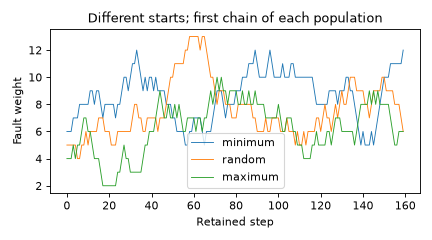

In [3]:
rng = np.random.default_rng(direct_seed)
failed_weights = []
for _ in range(450 if QUICK else 1800):
    state = problem.state(problem.noise.sample(p, rng))
    if problem.is_faulty(state):
        failed_weights.append(np.count_nonzero(state))
assert len(failed_weights) >= 2
direct_variance = float(np.var(failed_weights, ddof=1))
assert direct_variance > 0
screen = evaluate_convergence(runs[0], other_initialization=runs[1],
                              direct_variance=direct_variance)
print(f"Independent failed direct draws={len(failed_weights)}; conditional variance={direct_variance:.4f}")
for name, check in screen["checks"].items():
    print(f"{name}: {check['ok']}; details={check}")
print("Overall finite-budget screen:", screen["converged"])
print("Warnings:", *screen["warnings"], sep="\n- ")
fig, ax = plt.subplots(figsize=(5.4, 3.0))
for label, values in zip(("minimum", "random", "maximum"), weights):
    ax.plot(values[0], lw=.8, label=label)
ax.set(xlabel="Retained step", ylabel="Fault weight", title="Different starts; first chain of each population")
ax.legend()
fig.tight_layout()
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=80)
display(Image(data=buffer.getvalue()))
plt.close(fig)